## 03-Classification: homework

In [95]:
import pandas as pd
from sklearn.feature_extraction import DictVectorizer
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mutual_info_score
from sklearn.linear_model import LogisticRegression
import numpy as np

### Data preparation

In [67]:
data = pd.read_csv("course_lead_scoring_2026.csv")

In [14]:
data.isna().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [4]:
data.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [68]:
# imputing missing values
categorical = ["lead_source", "industry", "employment_status", "location"]
numerical = ["annual_income", "number_of_courses_viewed", 
             "interaction_count", "lead_score"]

for col in data.columns:
    data[[col]] = data[[col]].fillna('NA' if col in categorical else 0.0)

### Question 1

In [23]:
data.industry.value_counts().index[0]

'technology'

### Question 2

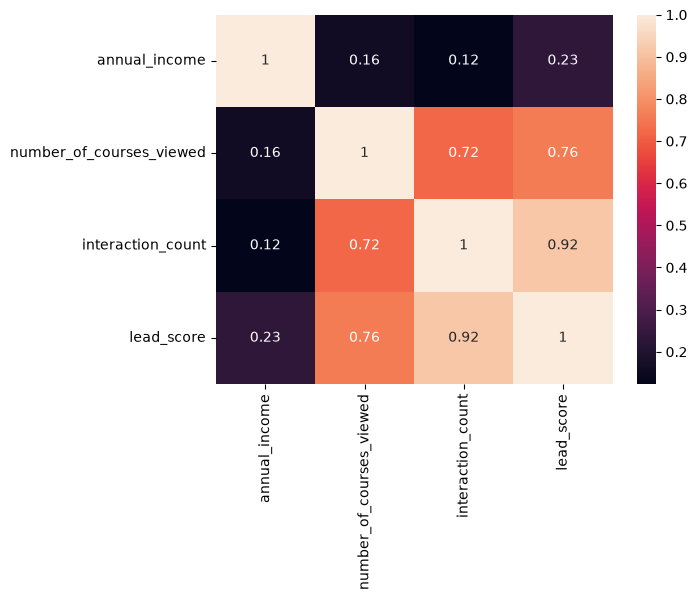

In [63]:
sns.heatmap(data.loc[:, numerical].corr(), annot = True)
plt.show()

### Train test split

In [76]:
df_full_train, df_test = train_test_split(data, test_size=0.2, random_state=42) #.drop(columns = "converted")
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=42
)

y_train = df_train["converted"].copy()
df_train = df_train.drop(columns = "converted")

y_val = df_val["converted"].copy()
df_val = df_val.drop(columns = "converted")

y_test = df_test["converted"].copy()
df_test = df_test.drop(columns = "converted")

### Question 3

In [77]:
df_train.loc[:, categorical].apply(
    lambda col: round(mutual_info_score(col, y_train),2),
    axis=0
)

lead_source          0.03
industry             0.00
employment_status    0.02
location             0.00
dtype: float64

### Question 4

In [85]:
### OHE for categorical variables
dv = DictVectorizer(sparse = False)
X_train = dv.fit_transform(df_train.to_dict(orient='records'))


def onehot_encode(df):
    return dv.transform(df.to_dict(orient='records'))

X_val = onehot_encode(df_val)
X_test = onehot_encode(df_test)

In [92]:
### model training
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42).fit(X_train, y_train)
y_pred_train = model.predict(X_train)
y_pred_val = model.predict(X_val)

In [98]:
val_acc = np.mean(y_val == y_pred_val)
print("Accuracy on validation dataset:", round(val_acc,2))

Accuracy on validation dataset: 0.64


### Question 5

In [101]:
data.columns

Index(['lead_source', 'industry', 'employment_status', 'location',
       'annual_income', 'number_of_courses_viewed', 'interaction_count',
       'lead_score', 'converted'],
      dtype='str')

In [105]:
results = []   
    
def onehot_encode(df):
    return dv.transform(df.to_dict(orient='records'))

for feature in data.columns[:-1]:

    df_full_train, df_test = train_test_split(data.drop(columns = [feature]), test_size=0.2, random_state=42) #.drop(columns = "converted")
    df_train, df_val = train_test_split(
        df_full_train, test_size=0.25, random_state=42
    )
    
    y_train = df_train["converted"].copy()
    df_train = df_train.drop(columns = "converted")
    
    y_val = df_val["converted"].copy()
    df_val = df_val.drop(columns = "converted")
    
    y_test = df_test["converted"].copy()
    df_test = df_test.drop(columns = "converted")


    dv = DictVectorizer(sparse = False)
    X_train = dv.fit_transform(df_train.to_dict(orient='records'))
    
    X_val = onehot_encode(df_val)
    X_test = onehot_encode(df_test)
    
    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42) \
        .fit(X_train, y_train)
    y_pred_train = model.predict(X_train)
    y_pred_val = model.predict(X_val)
    acc = np.mean(y_val == y_pred_val)
    results.append({"feature": feature, 
                    "accuracy:": acc,
                   "accuracy_change": val_acc - acc})

pd.DataFrame(results)

,feature,accuracy:,accuracy_change
0,lead_source,0.642,0.003
1,industry,0.645,0.000
2,employment_status,0.645,0.000
3,location,0.645,0.000
4,annual_income,0.724,-0.079
5,number_of_courses_viewed,0.643,0.002
6,interaction_count,0.601,0.044
7,lead_score,0.644,0.001


### Question 6

In [106]:
C = [0.000001, 0.00001, 0.0001, 0.001]

In [107]:
results = [] 

df_full_train, df_test = train_test_split(data.drop(columns = [feature]), test_size=0.2, random_state=42) #.drop(columns = "converted")
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=42
)

y_train = df_train["converted"].copy()
df_train = df_train.drop(columns = "converted")

y_val = df_val["converted"].copy()
df_val = df_val.drop(columns = "converted")

y_test = df_test["converted"].copy()
df_test = df_test.drop(columns = "converted")


dv = DictVectorizer(sparse = False)
X_train = dv.fit_transform(df_train.to_dict(orient='records'))

X_val = onehot_encode(df_val)
X_test = onehot_encode(df_test)

for c in C:
    
    model = LogisticRegression(solver='liblinear', C=c, max_iter=1000, random_state=42) \
        .fit(X_train, y_train)
    y_pred_val = model.predict(X_val)
    acc = np.mean(y_val == y_pred_val)
    results.append({"C": c, 
                    "accuracy:": acc})

pd.DataFrame(results)

,C,accuracy:
0,0.000001,0.598
1,0.000010,0.598
2,0.000100,0.613
3,0.001000,0.644
